# Incremental MeshA*

MeshA* (Agranovskiy and Yakovlev, [arXiv:2412.10320](https://arxiv.org/html/2412.10320v2)) plans a minimum-cost
sequence of motion primitives on an occupancy grid. LBA* searches the lattice whose edges are the primitives.
MeshA* searches *extended cells* (a cell plus the bundle of primitives still sweeping through it), so primitives
that share the first cells of their trace are collision-checked once. Intermediate mesh steps cost 0 and the
primitive's length is charged when the bundle reaches its end heading.

This notebook makes the problem **incremental**: after a plan is found an obstacle appears on it, the agent stops
a few cells short, and replans to the same goal; then a second obstacle hits the repaired plan. It compares

* **one-shot planners**, which solve each query from scratch: LBA*, LazyLBA*, MeshA* and Mesh/ParallA*
  (the paper's baselines and variants), and
* **incremental planners**, which keep their search between queries: D* Lite on the lattice and
  D* Lite on the mesh graph (incremental MeshA*).

The maps are **not** the paper's maps (it uses Labyrinth, ht_0_hightown, Moscow_0_512 and one unnamed map;
movingai.com was not reachable from the machine that ran this). The paper does not say what language its planner
is written in.

In [1]:
%matplotlib inline
import json
from collections import defaultdict

import matplotlib.pyplot as plt
import numpy as np

from mesha.benchmark import (BENCH_PATH, DISPLAY, INCREMENTAL, ONE_SHOT, RESULTS_PATH, ROOT, WEIGHTS,
                             apply_blocks, load_benchmark, load_named_maps)
from mesha.mesh import build_mesh
from mesha.primitives import build_control_set
from mesha.search import search
from mesha.viz import COLORS, draw_control_set, draw_map, draw_solution, grouped_bars, use_style

use_style()
benchmark = load_benchmark()
results = json.loads(RESULTS_PATH.read_text())
legacy = json.loads((ROOT / "results" / "legacy8_ablation.json").read_text())
records = results["records"]
maps = load_named_maps(benchmark)
control = build_control_set(benchmark["control_set"]["name"])
mesh = build_mesh(control)
topos = [row["topology"] for row in benchmark["maps"]]
instances = {inst["id"]: inst for inst in benchmark["instances"]}

def q(values, p):
    values = [v for v in values if v is not None and np.isfinite(v)]
    return float(np.percentile(values, p)) if values else float("nan")

def stats(values):
    return (q(values, 50), q(values, 25), q(values, 75))

print(json.dumps(results["meta"], indent=1))

{
 "python": "3.13.17",
 "numpy": "2.5.3",
 "platform": "Linux-6.18.44-fc-v153-x86_64-with-glibc2.39",
 "cpu": "Intel(R) Xeon(R) Processor @ 2.10GHz",
 "cpu_count": 4,
 "date": "2026-10-26T11:49:39+00:00",
 "repeats": 3,
 "workers": 3,
 "weights": [
  1.0,
  1.1,
  2.0,
  5.0,
  10.0
 ],
 "control_set": "car16",
 "wall_s": 4978.9520468989995,
 "instances": 187
}


## Maps, control set and instances

Berlin_2_256 and AR0700SR are MovingAI maps with their scenario files; the maze and the rooms are generated.
Pairs are spread evenly over path length, and each pair gets three random start/goal heading draws, as in the paper.

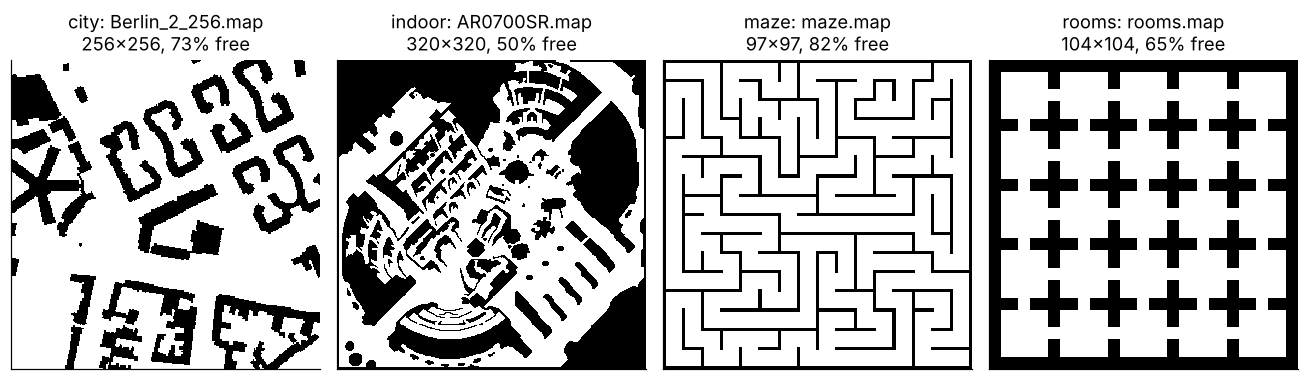

control set car16: 16 headings, 284 primitives (68 redundant ones removed), turning radius 2.0, 412 mesh configurations


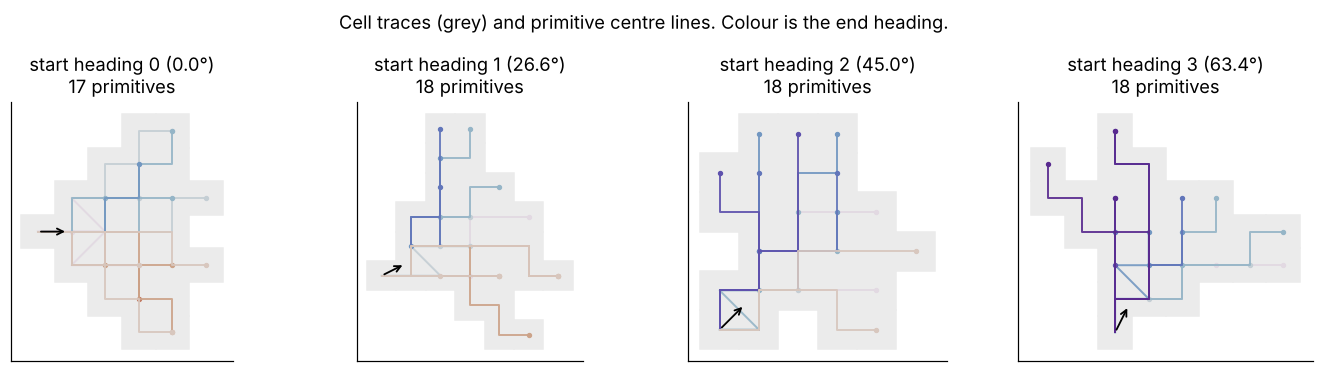


map                 pairs  draws  no path  edit failed  kept
Berlin_2_256.map       22     66       11            3    52
AR0700SR.map           21     63       15            0    48
maze.map               23     69       30            0    39
rooms.map              22     66       18            0    48
total instances: 187, queries: 561


In [2]:
fig, axes = plt.subplots(1, 4, figsize=(12, 3.4))
for ax, row in zip(axes, benchmark["maps"]):
    draw_map(ax, maps[row["file"]], f"{row['topology']}: {row['file']}")
fig.tight_layout(); plt.show()

cs = benchmark["control_set"]
print(f"control set {cs['name']}: {cs['headings']} headings, {cs['primitives']} primitives "
      f"({cs['removed_dominated']} redundant ones removed), turning radius {cs['turning_radius']}, "
      f"{cs['configurations']} mesh configurations")
fig = draw_control_set(control); plt.show()

print(f"\n{'map':<18}{'pairs':>7}{'draws':>7}{'no path':>9}{'edit failed':>13}{'kept':>6}")
for name, log in benchmark["selection"].items():
    print(f"{name:<18}{log['pairs_considered']:>7}{log['heading_draws']:>7}{log['no_solution']:>9}"
          f"{log['edit_failed']:>13}{log['kept']:>6}")
print(f"total instances: {len(benchmark['instances'])}, queries: {3 * len(benchmark['instances'])}")

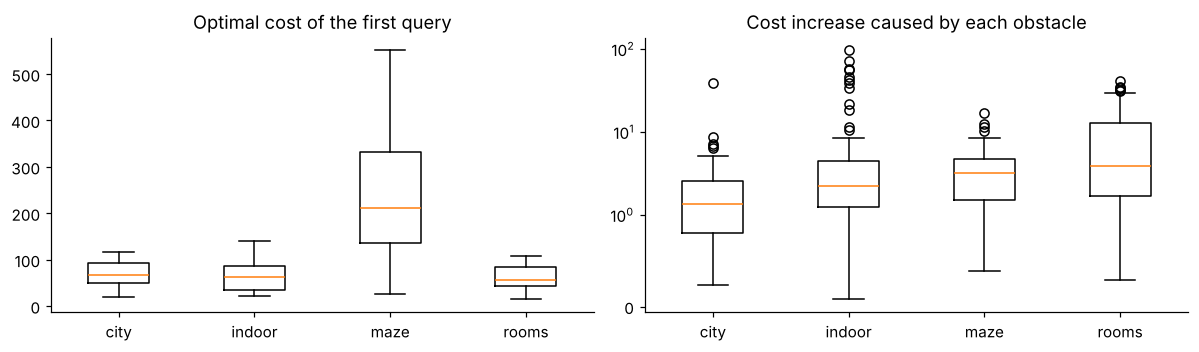

edits: 374, median increase 2.32, no change (<0.01): 0, >5: 83


In [3]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.3))
lengths = defaultdict(list)
incs = defaultdict(list)
for inst in benchmark["instances"]:
    lengths[inst["topology"]].append(inst["reference_cost"])
    for query in inst["queries"][1:]:
        incs[inst["topology"]].append(query["edit"]["increase"])
axes[0].boxplot([lengths[t] for t in topos], tick_labels=topos)
axes[0].set_title("Optimal cost of the first query")
axes[1].boxplot([incs[t] for t in topos], tick_labels=topos)
axes[1].set_yscale("symlog", linthresh=1)
axes[1].set_title("Cost increase caused by each obstacle")
fig.tight_layout(); plt.show()
allinc = [v for t in topos for v in incs[t]]
print(f"edits: {len(allinc)}, median increase {np.median(allinc):.2f}, "
      f"no change (<0.01): {sum(v < 0.01 for v in allinc)}, >5: {sum(v > 5 for v in allinc)}")

## Correctness

At `w = 1` LBA*, LazyLBA* and MeshA* solve the same optimisation problem and must agree. The runner already
stops if either D* Lite planner disagrees with the from-scratch optimum on any query. Mesh/ParallA* is not
optimal by design (soft-duplicate pruning), so its overhead is reported instead.

In [4]:
by = defaultdict(dict)
for r in records:
    if r["kind"] == "oneshot":
        by[(r["id"], r["query"], r["weight"])][r["algorithm"]] = r
mismatch = 0
for (ident, qi, w), algos in by.items():
    if w != 1.0:
        continue
    costs = [algos[a]["cost"] for a in ("lba", "lazy_lba", "mesha")]
    if None in costs or max(costs) - min(costs) > 1e-6:
        mismatch += 1
print(f"optimal-cost disagreements among LBA*/LazyLBA*/MeshA*: {mismatch}")
assert mismatch == 0
inc_rows = [r for r in records if r["kind"] == "incremental"]
print(f"incremental replans checked against the optimum: {len(inc_rows)} (all matched)")
capped = [r for r in records if r.get("capped")]
print(f"capped runs: {len(capped)}")
over = [by[k]["mesh_parall"]["cost"] / by[k]["lba"]["cost"] for k in by if k[2] == 1.0 and by[k]["lba"]["cost"]]
print(f"Mesh/ParallA* at w=1: median {100*np.median(over):.1f}% of optimal, mean {100*np.mean(over):.1f}%, "
      f"optimal in {sum(o < 1 + 1e-9 for o in over)}/{len(over)} queries")

optimal-cost disagreements among LBA*/LazyLBA*/MeshA*: 0
incremental replans checked against the optimum: 1122 (all matched)
capped runs: 0
Mesh/ParallA* at w=1: median 100.8% of optimal, mean 111.1%, optimal in 168/561 queries


## One-shot planners on the original query (the paper's setting)

Ratios are per query, against the same query's LBA* (runtime) or LazyLBA* (collision checks, as in the paper's
Fig. 5); bars are medians, whiskers the interquartile range. Times are the median of three runs. The paper reports
MeshA* at 60-80% of LBA* runtime at `w = 1` (C++ or similar compiled code is likely; the paper does not say).

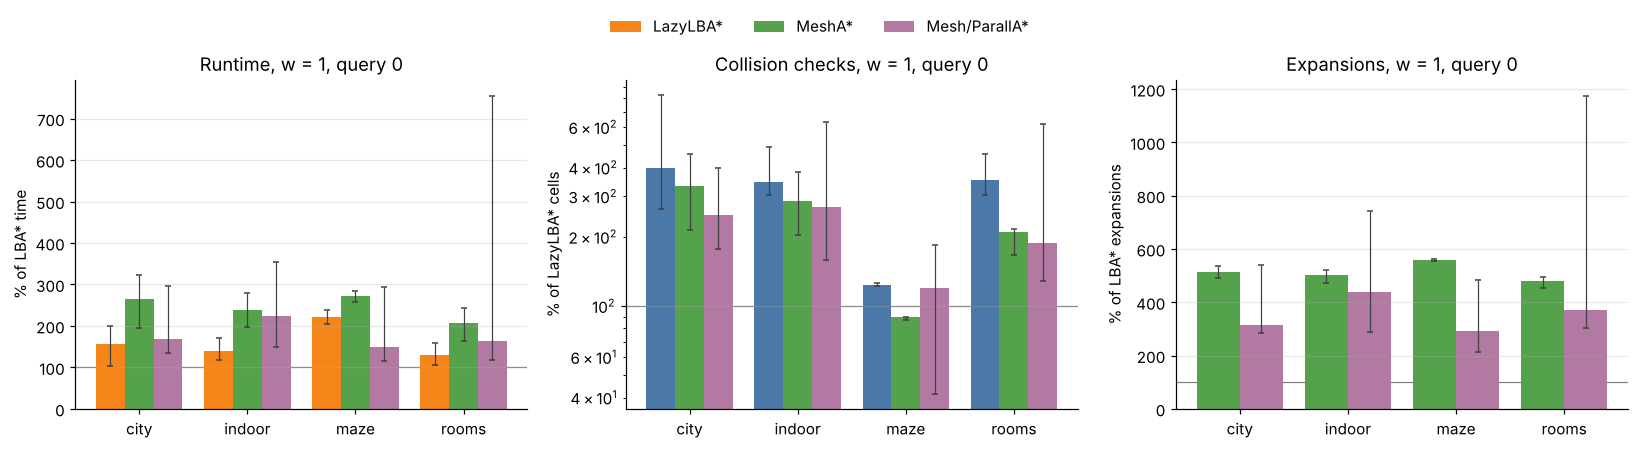

LazyLBA*        time  156.0% of LBA*   cells   30.8% of LBA*,  100.0% of LazyLBA*
MeshA*          time  245.6% of LBA*   cells   70.3% of LBA*,  210.3% of LazyLBA*
Mesh/ParallA*   time  170.1% of LBA*   cells   63.4% of LBA*,  201.0% of LazyLBA*


In [5]:
def paired(metric, base, weight=1.0, queries=(0,), algos=ONE_SHOT):
    out = {t: defaultdict(list) for t in topos}
    for (ident, qi, w), a in by.items():
        if w != weight or qi not in queries or a[base]["cost"] is None:
            continue
        b = a[base][metric]
        if not b:
            continue
        for name in algos:
            if a[name]["success"]:
                out[instances[ident]["topology"]][name].append(a[name][metric] / b)
    return out

def bars(ratio, algos, ax, ylabel, title):
    grouped_bars(ax, topos, {n: [tuple(100 * v for v in stats(ratio[t][n])) for t in topos] for n in algos},
                 ylabel, title)
    ax.axhline(100, color="0.5", lw=0.8, zorder=0)

fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))
bars(paired("time_median", "lba"), ["lazy_lba", "mesha", "mesh_parall"], axes[0], "% of LBA* time",
     "Runtime, w = 1, query 0")
bars(paired("checked_cells", "lazy_lba"), ["lba", "mesha", "mesh_parall"], axes[1], "% of LazyLBA* cells",
     "Collision checks, w = 1, query 0")
bars(paired("expansions", "lba"), ["mesha", "mesh_parall"], axes[2], "% of LBA* expansions",
     "Expansions, w = 1, query 0")
axes[1].set_yscale("log")
h, l = axes[0].get_legend_handles_labels()
fig.legend(h, l, loc="upper center", ncol=4, frameon=False, bbox_to_anchor=(0.5, 1.08))
fig.tight_layout(); plt.show()

def overall(ratio, name):
    return 100 * np.median([v for t in topos for v in ratio[t][name]])

tr, cr, er = paired("time_median", "lba"), paired("checked_cells", "lazy_lba"), paired("expansions", "lba")
cl = paired("checked_cells", "lba")
for name in ("lazy_lba", "mesha", "mesh_parall"):
    print(f"{DISPLAY[name]:<15} time {overall(tr, name):6.1f}% of LBA*   cells {overall(cl, name):6.1f}% of LBA*, "
          f"{overall(cr, name):6.1f}% of LazyLBA*")

### How LBA* checks primitives matters

Our LBA* checks a primitive only if its successor is not closed and would improve its g-value. A textbook LBA*
checks every primitive of an expanded state first. Costs and expansions are identical; collision checks are not.
On every fourth instance (query 0, `w = 1`):

In [6]:
sample = benchmark["instances"][::4]
ratio_default, ratio_textbook = [], []
for inst in sample:
    qq = inst["queries"][0]
    g = maps[inst["map"]]
    d = search("lba", g, control, qq["start"], qq["goal"], mesh)
    t = search("lba", g, control, qq["start"], qq["goal"], mesh, lba_check_all=True)
    m = by[(inst["id"], 0, 1.0)]["mesha"]
    ratio_default.append(m["checked_cells"] / d.checked_cells)
    ratio_textbook.append(m["checked_cells"] / t.checked_cells)
print(f"{len(sample)} instances: MeshA* cells = {100*np.median(ratio_default):.0f}% of our LBA*, "
      f"{100*np.median(ratio_textbook):.0f}% of textbook LBA*")

47 instances: MeshA* cells = 69% of our LBA*, 28% of textbook LBA*


### Runtime against path length

Interpreter overhead per node is larger for MeshA* (one queue node per cell of every primitive). The ratio
below shows whether that changes with problem size.

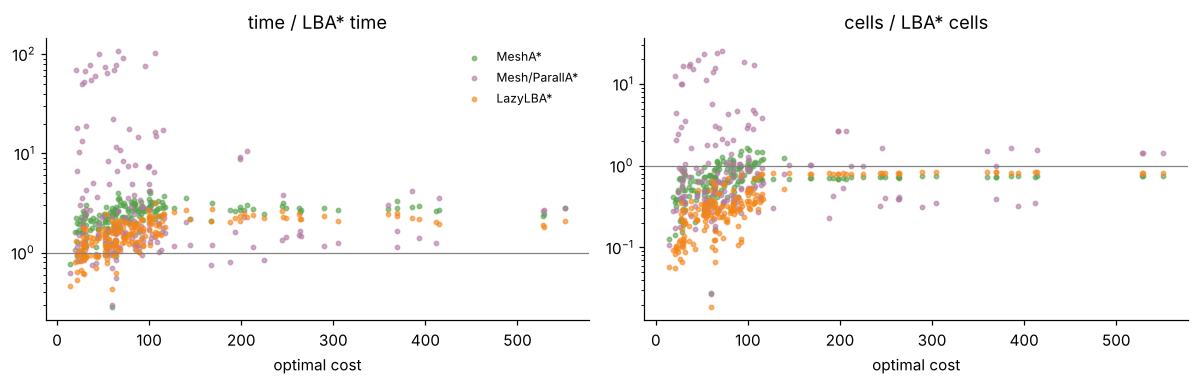

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
for name in ("mesha", "mesh_parall", "lazy_lba"):
    xs, ys = [], []
    for (ident, qi, w), a in by.items():
        if w == 1.0 and qi == 0 and a["lba"]["cost"]:
            xs.append(a["lba"]["cost"]); ys.append(a[name]["time_median"] / a["lba"]["time_median"])
    axes[0].scatter(xs, ys, s=8, alpha=0.6, color=COLORS[name], label=DISPLAY[name])
    xs2 = [a["lba"]["cost"] for (i, qi, w), a in by.items() if w == 1.0 and qi == 0 and a["lba"]["cost"]]
    ys2 = [a[name]["checked_cells"] / max(1, a["lba"]["checked_cells"]) for (i, qi, w), a in by.items()
           if w == 1.0 and qi == 0 and a["lba"]["cost"]]
    axes[1].scatter(xs2, ys2, s=8, alpha=0.6, color=COLORS[name], label=DISPLAY[name])
for ax, t in zip(axes, ("time / LBA* time", "cells / LBA* cells")):
    ax.axhline(1, color="0.5", lw=0.8); ax.set_yscale("log"); ax.set_xlabel("optimal cost"); ax.set_title(t)
axes[0].legend(frameon=False, fontsize=8)
fig.tight_layout(); plt.show()

## Weighted search

Median solution cost as % of optimal (the paper's Table 1) and median runtime as % of LBA* at the same weight
(the paper's Fig. 4), over all three queries.

cost % of optimal     w=1.0    w=1.1    w=2.0    w=5.0   w=10.0
LBA*                  100.0    100.3    104.1    108.9    112.0
LazyLBA*              100.0    100.3    104.1    108.9    112.0
MeshA*                100.0    100.9    106.0    110.7    114.0
Mesh/ParallA*         100.8    102.0    108.2    113.0    115.9

time % of LBA*        w=1.0    w=1.1    w=2.0    w=5.0   w=10.0
LazyLBA*              129.0    115.3    102.7    102.7    104.2
MeshA*                199.6    187.5    141.2    132.0    130.2
Mesh/ParallA*         170.2    177.5    149.3    148.2    149.5


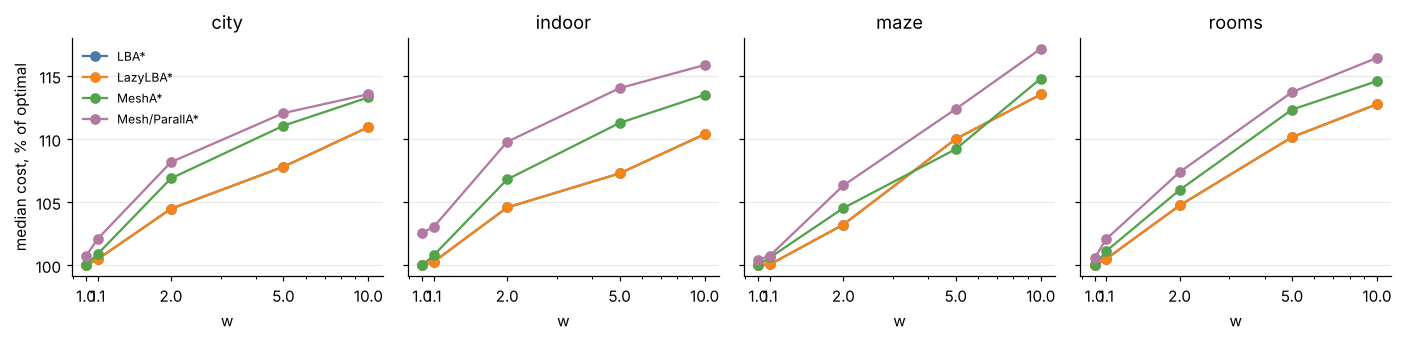

In [8]:
opt = {(k[0], k[1]): a["lba"]["cost"] for k, a in by.items() if k[2] == 1.0}
print(f"{'cost % of optimal':<18}" + "".join(f"{'w=' + str(w):>9}" for w in WEIGHTS))
for name in ONE_SHOT:
    row = []
    for w in WEIGHTS:
        vals = [a[name]["cost"] / opt[(k[0], k[1])] for k, a in by.items()
                if k[2] == w and a[name]["success"] and opt.get((k[0], k[1]))]
        row.append(100 * np.median(vals))
    print(f"{DISPLAY[name]:<18}" + "".join(f"{v:9.1f}" for v in row))
print()
print(f"{'time % of LBA*':<18}" + "".join(f"{'w=' + str(w):>9}" for w in WEIGHTS))
for name in ONE_SHOT[1:]:
    row = []
    for w in WEIGHTS:
        vals = [a[name]["time_median"] / a["lba"]["time_median"] for k, a in by.items()
                if k[2] == w and a[name]["success"] and a["lba"]["time_median"] > 0]
        row.append(100 * np.median(vals))
    print(f"{DISPLAY[name]:<18}" + "".join(f"{v:9.1f}" for v in row))

fig, axes = plt.subplots(1, 4, figsize=(13, 3.2), sharey=True)
for ax, topo in zip(axes, topos):
    for name in ONE_SHOT:
        ys = []
        for w in WEIGHTS:
            vals = [a[name]["cost"] / opt[(k[0], k[1])] for k, a in by.items()
                    if k[2] == w and a[name]["success"] and instances[k[0]]["topology"] == topo]
            ys.append(100 * np.median(vals))
        ax.plot(WEIGHTS, ys, marker="o", color=COLORS[name], label=DISPLAY[name])
    ax.set_xscale("log"); ax.set_xticks(WEIGHTS, [str(w) for w in WEIGHTS]); ax.set_title(topo)
    ax.grid(axis="y", alpha=0.3); ax.set_xlabel("w")
axes[0].set_ylabel("median cost, % of optimal"); axes[0].legend(frameon=False, fontsize=8)
fig.tight_layout(); plt.show()

### Ablation: the legacy8 control set

Does the gap between weighted MeshA* and LBA* depend on the control set? The same planners with the simplified
8-heading legacy8 set, whose long primitives are all chains of 1-step primitives, on its own 32 instances:

In [9]:
lopt = {(r["id"], r["query"]): r["cost"] for r in legacy["records"] if r["algorithm"] == "lba" and r["weight"] == 1.0}
lw = sorted({r["weight"] for r in legacy["records"]})
print(f"{'legacy8 cost %':<18}" + "".join(f"{'w=' + str(w):>9}" for w in lw))
for name in ONE_SHOT:
    row = []
    for w in lw:
        vals = [r["cost"] / lopt[(r["id"], r["query"])] for r in legacy["records"]
                if r["algorithm"] == name and r["weight"] == w and r["success"]]
        row.append(100 * np.median(vals))
    print(f"{DISPLAY[name]:<18}" + "".join(f"{v:9.1f}" for v in row))

legacy8 cost %        w=1.0    w=2.0    w=5.0   w=10.0
LBA*                  100.0    103.4    108.1    113.3
LazyLBA*              100.0    103.4    108.1    113.3
MeshA*                100.0    100.0    100.0    100.0
Mesh/ParallA*         100.0    100.0    100.0    100.0


## Incremental replanning

For queries 1 and 2 the one-shot planners start from scratch, while the D* Lite planners repair the search
they already have. Query 0 is a full search for everyone (D* Lite searches backward from the goal, so its first
search is comparable to a backward A*).

In [10]:
rows = defaultdict(dict)
for r in records:
    if r["weight"] == 1.0:
        rows[(r["id"], r["query"])][r["algorithm"]] = r
algos = ["lba", "mesha", "dstar_lattice", "dstar_mesh"]
for metric, label in (("expansions", "expansions"), ("checked_cells", "collision checks"), ("time_median", "time [s]")):
    print(f"median {label}")
    print(f"  {'query':<8}" + "".join(f"{DISPLAY[a]:>20}" for a in algos))
    for qi in (0, 1, 2):
        vals = [np.median([rows[k][a][metric] for k in rows if k[1] == qi]) for a in algos]
        print(f"  {qi:<8}" + "".join(f"{v:20.4g}" for v in vals))
    print()

median expansions
  query                   LBA*              MeshA*   D* Lite (lattice)      D* Lite (mesh)
  0                       8293           4.057e+04                6925           1.066e+05
  1                       2353           1.148e+04                 379                4460
  2                        959                4135                 415                4913

median collision checks
  query                   LBA*              MeshA*   D* Lite (lattice)      D* Lite (mesh)
  0                   2.54e+05           1.929e+05           5.268e+05           1.927e+05
  1                  8.441e+04           4.839e+04           3.568e+04                2071
  2                  3.797e+04           1.513e+04            3.32e+04                2291

median time [s]
  query                   LBA*              MeshA*   D* Lite (lattice)      D* Lite (mesh)
  0                     0.1674              0.4055              0.3399               1.294
  1                    0.04793

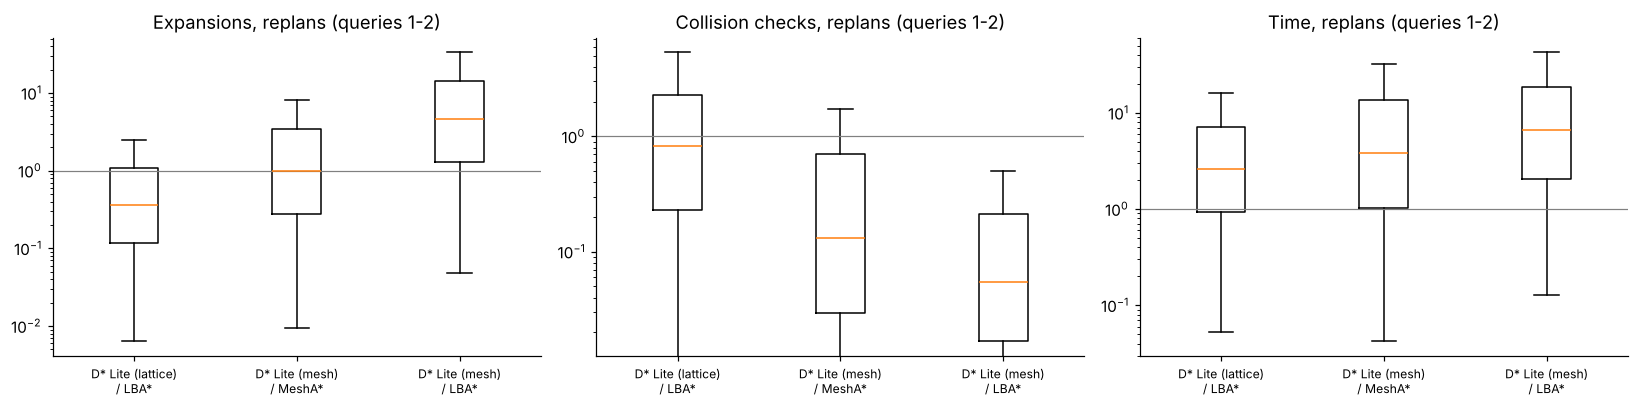

 D* Lite (lattice) / LBA*       expansions     median   0.363  IQR 0.118-1.086
 D* Lite (lattice) / LBA*       checked_cells  median   0.824  IQR 0.232-2.304
 D* Lite (lattice) / LBA*       time_median    median   2.605  IQR 0.924-7.100
    D* Lite (mesh) / MeshA*     expansions     median   0.994  IQR 0.280-3.486
    D* Lite (mesh) / MeshA*     checked_cells  median   0.132  IQR 0.029-0.708
    D* Lite (mesh) / MeshA*     time_median    median   3.851  IQR 1.033-13.594
    D* Lite (mesh) / LBA*       expansions     median   4.559  IQR 1.275-14.340
    D* Lite (mesh) / LBA*       checked_cells  median   0.055  IQR 0.017-0.212
    D* Lite (mesh) / LBA*       time_median    median   6.680  IQR 2.042-18.769


In [11]:
def ratio_vs(metric, num, den, queries):
    return [rows[k][num][metric] / rows[k][den][metric] for k in rows
            if k[1] in queries and rows[k][den][metric] > 0]

fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))
pairs = [("dstar_lattice", "lba"), ("dstar_mesh", "mesha"), ("dstar_mesh", "lba")]
for ax, metric, title in zip(axes, ("expansions", "checked_cells", "time_median"),
                             ("Expansions", "Collision checks", "Time")):
    data = [ratio_vs(metric, a, b, (1, 2)) for a, b in pairs]
    ax.boxplot(data, tick_labels=[f"{DISPLAY[a]}\n/ {DISPLAY[b]}" for a, b in pairs], showfliers=False)
    ax.axhline(1, color="0.5", lw=0.8); ax.set_yscale("log"); ax.set_title(f"{title}, replans (queries 1-2)")
    ax.tick_params(axis="x", labelsize=8)
fig.tight_layout(); plt.show()
for (a, b) in pairs:
    for metric in ("expansions", "checked_cells", "time_median"):
        v = ratio_vs(metric, a, b, (1, 2))
        print(f"{DISPLAY[a]:>18} / {DISPLAY[b]:<10} {metric:<14} median {np.median(v):7.3f}  "
              f"IQR {np.percentile(v, 25):.3f}-{np.percentile(v, 75):.3f}")

In [12]:
# by edit severity
buckets = [(0, 1, "< 1"), (1, 5, "1-5"), (5, 1e9, "> 5")]
print(f"{'cost increase':<14}{'n':>5}" + "".join(f"{DISPLAY[a] + ' / ' + DISPLAY[b]:>36}" for a, b in pairs[:2]))
for lo, hi, label in buckets:
    keys = [k for k in rows if k[1] > 0 and lo <= instances[k[0]]["queries"][k[1]]["edit"]["increase"] < hi]
    cells = []
    for a, b in pairs[:2]:
        v = [rows[k][a]["time_median"] / rows[k][b]["time_median"] for k in keys]
        cells.append(f"time x{np.median(v):.2f}, exp x{np.median([rows[k][a]['expansions'] / max(1, rows[k][b]['expansions']) for k in keys]):.2f}")
    print(f"{label:<14}{len(keys):>5}" + "".join(f"{c:>36}" for c in cells))

# per-episode totals
print()
tot = defaultdict(lambda: defaultdict(float))
for (ident, qi), a in rows.items():
    for name, r in a.items():
        tot[ident][name] += r["time_median"]
for a, b in (("dstar_lattice", "lba"), ("dstar_mesh", "mesha"), ("dstar_mesh", "lba"), ("mesha", "lba")):
    v = [tot[i][a] / tot[i][b] for i in tot]
    print(f"episode time {DISPLAY[a]:>18} / {DISPLAY[b]:<10} median {np.median(v):.3f}  IQR {np.percentile(v, 25):.3f}-{np.percentile(v, 75):.3f}")

cost increase     n            D* Lite (lattice) / LBA*             D* Lite (mesh) / MeshA*
< 1              70               time x2.16, exp x0.20               time x2.13, exp x0.43
1-5             221               time x2.47, exp x0.31               time x3.14, exp x0.79
> 5              83               time x3.40, exp x0.94               time x6.74, exp x3.76

episode time  D* Lite (lattice) / LBA*       median 2.411  IQR 1.672-5.250
episode time     D* Lite (mesh) / MeshA*     median 4.336  IQR 2.473-9.802
episode time     D* Lite (mesh) / LBA*       median 11.228  IQR 5.248-21.710
episode time             MeshA* / LBA*       median 2.424  IQR 1.976-2.718


## Example

The median-length city instance: MeshA* on the first query, and the repaired plan after each obstacle.

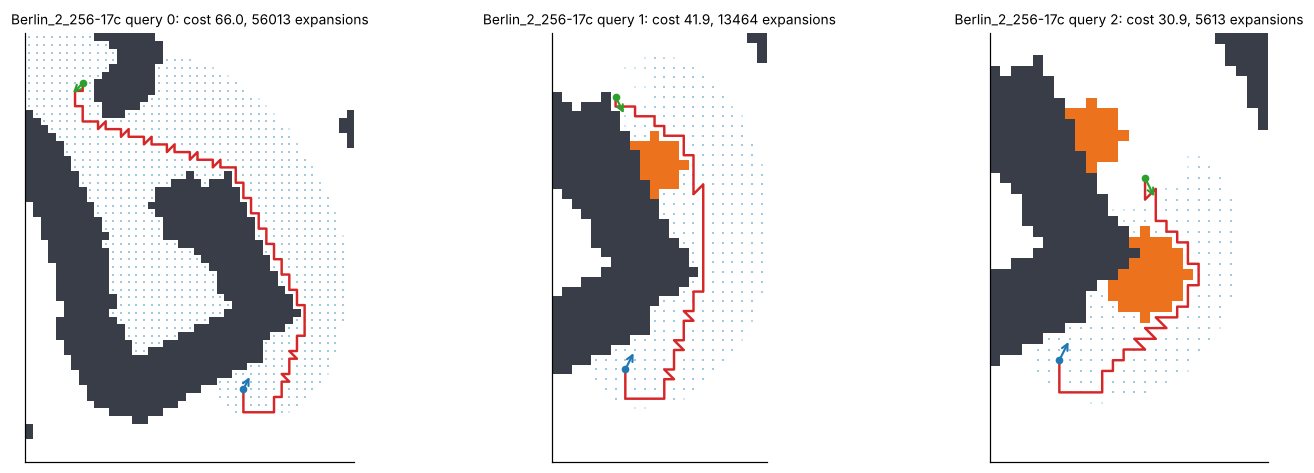

In [13]:
city = sorted([i for i in benchmark["instances"] if i["topology"] == "city"], key=lambda i: i["reference_cost"])
inst = city[len(city) // 2]
fig, axes = plt.subplots(1, 3, figsize=(14, 4.4))
for ax, (qi, query) in zip(axes, enumerate(inst["queries"])):
    grid = apply_blocks(maps[inst["map"]], query["blocks"])
    res = search("mesha", grid, control, query["start"], query["goal"], mesh, return_path=True)
    draw_solution(ax, grid, query["blocks"], query["start"], query["goal"], res.trace, res.expanded,
                  f"{inst['id']} query {qi}: cost {res.cost:.1f}, {res.expansions} expansions", control)
fig.tight_layout(); plt.show()

## Conclusions

Measured on 187 instances (561 queries) on four maps. The environment is printed at the top of the notebook. All
numbers are medians of per-query ratios unless stated.

**Correctness.** LBA*, LazyLBA* and MeshA* agree on the optimal cost of every query. All 1,122 incremental
replans (2 planners × 561 queries) match the from-scratch optimum. No run hit the expansion cap.

**One-shot planning (paper setting, `w = 1`, first query).**

* *Collision checks.* MeshA* reads 70% as many cells as our LBA*. The saving is largest on short paths (42% below
  cost 40) and shrinks on long ones (74% above cost 80). Against a textbook LBA* that checks every primitive
  before looking at g-values, MeshA* reads about 28% as many cells, which is closer to the paper's claim. In both
  cases MeshA* reads about 2× more cells than LazyLBA*. That is the opposite of the paper's Fig. 5. LazyLBA*
  checks only the primitives it pops, and in this control set most generated primitives are never popped.
* *Runtime (Python).* MeshA* takes 2.5× the time of LBA* (2.1× on rooms, 2.7× on the maze) and expands about
  5× more nodes, since every cell of a primitive is a queue entry. The paper's 60-80% of LBA* runtime is not
  reproduced here. In Python, per-node interpreter overhead outweighs the cheap grid reads this saves. The
  comparison that carries over to a compiled implementation is the collision-check count.
* *Mesh/ParallA*.* Median cost is 100.6% of optimal on the first query (100.8% over all 561 queries; paper:
  100.3-100.7%), optimal in 168 of 561 queries. It is faster than MeshA* (1.7× LBA* time instead of 2.5×), as in
  the paper.
* *LazyLBA*.* It is slower than LBA* (1.6× at `w = 1`), as the paper also finds. Grid reads are cheap, so
  checking fewer of them doesn't pay for the extra queue traffic.

**Weighted search.** With the car-like control set, weighted MeshA* is *more* suboptimal than LBA* (at w = 2 / 5
/ 10: 106.0 / 110.7 / 114.0% of optimal, against LBA*'s 104.1 / 108.9 / 112.0%). This is the paper's Table 1
trend. With the 8-heading legacy8 control set (on its own 32 instances), MeshA* stays at a median of 100% for
every weight, so that effect comes from the degenerate control set and not from the algorithm.

**Incremental replanning (queries 1-2, `w = 1`).**

* D* Lite on the lattice expands 0.36× as many states as LBA* from scratch and reads 0.82× as many cells, but
  takes 2.6× as long in Python.
* D* Lite on the mesh graph (incremental MeshA*) expands about as many nodes as MeshA* from scratch but reads
  only 13% as many cells. That is 5.5% of the cells LBA* reads. Its wall time is 3.9× MeshA*'s.
* The advantage fades as obstacles get more disruptive. Where an obstacle raises the optimal cost by more than 5,
  D* Lite on the mesh expands 3.8× more than MeshA* from scratch. Each replan here starts several primitives
  further along the path, and D* Lite has to repair a large part of its backward search tree.
* Summed over a whole episode, every incremental planner is slower in wall time than its from-scratch
  counterpart in this implementation.

**What this means.** Mesh-graph D* Lite cuts collision checking by more than an order of magnitude on replans.
That is the cost MeshA* is designed to save, and it is the expensive part when checks involve a real robot
footprint or a costly map query. With cheap grid reads in Python, bookkeeping dominates and both A* and D* Lite
lose in wall time. Two next steps would settle the runtime question: a compiled implementation, and the
paper's maps (not reachable from the machine that ran this; see the README).

**Limits.** The 561 queries fall well short of the paper's >25,000, and the maps are substitutes. The primitives
are Hermite curves, not the paper's optimised car primitives. Times are Python, measured with 3 workers on
4 cores.